# Kural — Complaint Theme Discovery (NLP Text Analysis)

This notebook applies natural language processing (NLP) to discover recurring complaint themes across 117,214 financial consumer narratives.

### Overview
Reading thousands of unstructured complaint narratives manually is impractical. Unsupervised topic modeling provides a systematic method to surface latent themes directly from the text customers write. Using TF-IDF vectorization and Non-negative Matrix Factorization (NMF), we identify 16 candidate complaint themes without manual pre-labeling.

In [1]:
import os
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Connect to project src
sys.path.append(str(Path('../src').resolve()))
from text_analysis import (
    prepare_nlp_text,
    fit_topic_model,
    extract_topic_keywords,
    assign_topics,
    generate_topic_summary_tables,
    generate_topic_visualizations
)

figures_dir = Path('../outputs/figures')
tables_dir = Path('../outputs/tables')
data_path = Path('../data/processed/complaints_with_topics.csv.gz')

figures_dir.mkdir(parents=True, exist_ok=True)
tables_dir.mkdir(parents=True, exist_ok=True)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

print(f"Data path exists: {data_path.exists()}")

Data path exists: True


## Text Preparation

Before modeling, complaint text must be preprocessed specifically for topic discovery:
1. **Redaction Placeholder Removal:** CFPB narratives contain masking tokens such as `XXXX`, `XX/XX/XXXX`, and isolated `x` characters. If left untreated, these tokens contaminate topic keywords with meaningless artifacts. Our preprocessing strips these redactions.
2. **Whitespace and Case Normalization:** Lowercasing and collapsing whitespace ensure terms are standardized across diverse consumer writing styles.
3. **Punctuation Stripping:** Punctuation characters that do not assist theme discovery are removed while alphanumeric characters are preserved.
4. **Financial Vocabulary Preservation:** Key financial terms (such as credit, debt, account, payment, interest, mortgage) are explicitly protected from over-aggressive stop-word filtering.

In [2]:
# Load processed complaints with assigned topics
df = pd.read_csv(data_path)
print(f"Loaded dataset: {len(df):,} complaints, {len(df.columns)} columns.")
print("Assigned topic columns:", [c for c in df.columns if 'topic' in c])
display(df[['complaint_id', 'product', 'topic_id', 'topic_weight', 'cleaned_narrative']].head(3))

Loaded dataset: 117,214 complaints, 28 columns.
Assigned topic columns: ['topic_id', 'topic_weight']


,complaint_id,product,topic_id,topic_weight,cleaned_narrative
0,3384392,Debt collection,topic_08,0.046406,transworld systems inc. is trying to collect a...
1,3417821,"Credit reporting, credit repair services, or o...",topic_06,0.027766,i would like to request the suppression of the...
2,3433198,Debt collection,topic_07,0.038824,"over the past 2 weeks, i have been receiving e..."


## Topic Modeling

We use established, transparent linear algebra techniques for topic discovery:

### 1. TF-IDF Representation
- **Term Frequency-Inverse Document Frequency (TF-IDF)** converts text into a numeric feature matrix.
- **Configuration:** Unigrams and bigrams (`ngram_range=(1, 2)`), English stop words removed, `min_df=10` (terms must appear in at least 10 documents), `max_df=0.85` (terms appearing in over 85% of documents excluded), and vocabulary capped at `max_features=15000` with `sublinear_tf=True` (logarithmic term frequency scaling).

### 2. Non-negative Matrix Factorization (NMF)
- **NMF** decomposes the non-negative matrix $V \approx W H$, where $W$ represents document-topic weights and $H$ represents topic-term weights.
- **Configuration:** $k = 16$ candidate topics, deterministic Non-negative Double Singular Value Decomposition (`init="nndsvda"`), `random_state=42`, and `max_iter=350`.

### 3. Duplicate Narrative Handling
- The topic model was trained strictly on **distinct** prepared narrative texts ($101,800$ unique texts) so repetitive dispute form letters would not dominate vocabulary extraction.
- The fitted model was then applied across all $117,214$ valid complaints, ensuring identical narratives receive identical topic assignments.

## Topic Results

Below we review the representative keywords and complaint volumes across the 16 candidate topics.

=== TOPIC KEYWORDS (TOP 12 REPRESENTATIVE TERMS) ===


,topic_id,top_keywords,complaint_count
0,topic_01,"told, called, said, received, did, asked, sent...",6824
1,topic_02,"report, credit report, credit, removed, remove...",9560
2,topic_03,"past, 00 past, balance 00, 00 balance, balance...",1038
3,topic_04,"card, credit card, credit, cards, charges, cha...",8119
4,topic_05,"loan, mortgage, payments, loans, payment, 00, ...",16570
5,topic_06,"theft, identity, identity theft, victim, victi...",5456
6,topic_07,"phone, number, calls, calling, times, phone nu...",5484
7,topic_08,"debt, collection, company, agency, collection ...",12933
8,topic_09,"late, payment, payments, late payment, days la...",6380
9,topic_10,"inquiry, inquiries, hard, hard inquiry, unauth...",5647



=== TOPIC DISTRIBUTION ===


,topic_id,complaint_count,percentage
0,topic_01,6824,5.82
1,topic_02,9560,8.16
2,topic_03,1038,0.89
3,topic_04,8119,6.93
4,topic_05,16570,14.14
5,topic_06,5456,4.65
6,topic_07,5484,4.68
7,topic_08,12933,11.03
8,topic_09,6380,5.44
9,topic_10,5647,4.82


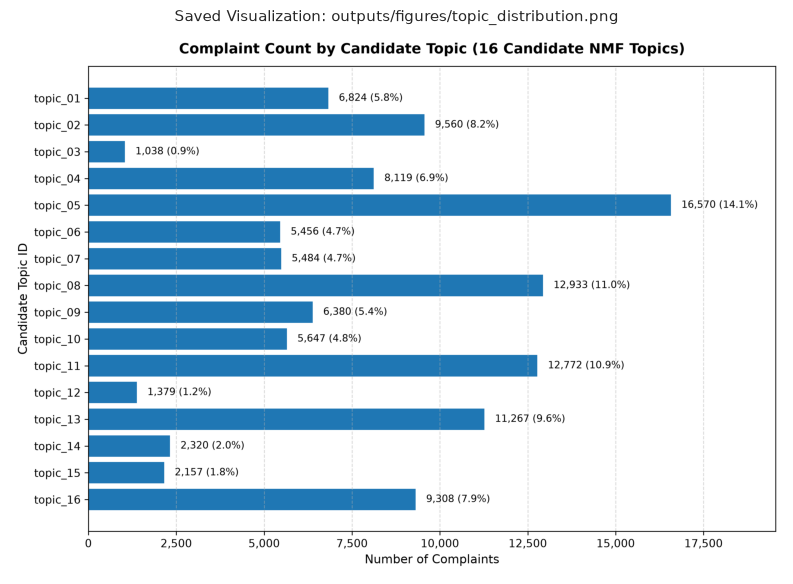

In [3]:
# Load Topic Keywords and Distribution Tables
df_keywords = pd.read_csv(tables_dir / 'topic_keywords.csv')
df_dist = pd.read_csv(tables_dir / 'topic_distribution.csv')

print("=== TOPIC KEYWORDS (TOP 12 REPRESENTATIVE TERMS) ===")
display(df_keywords)

print("\n=== TOPIC DISTRIBUTION ===")
display(df_dist)

# Display Topic Distribution Figure
dist_img = plt.imread(figures_dir / 'topic_distribution.png')
fig, ax = plt.subplots(figsize=(10, 7))
ax.imshow(dist_img)
ax.axis('off')
plt.title('Saved Visualization: outputs/figures/topic_distribution.png', fontsize=11, pad=10)
plt.show()

## Business Comparisons

We analyze how candidate topics are distributed across financial products and how recorded relief rates compare across topics.

=== TOPICS AND RECORDED RELIEF ===


,topic_id,total_complaints,complaints_with_recorded_relief,recorded_relief_percentage
0,topic_01,6824,1228,18.00
1,topic_02,9560,2174,22.74
2,topic_03,1038,122,11.75
3,topic_04,8119,2048,25.22
4,topic_05,16570,1349,8.14
5,topic_06,5456,1646,30.17
6,topic_07,5484,1140,20.79
7,topic_08,12933,1295,10.01
8,topic_09,6380,971,15.22
9,topic_10,5647,1056,18.70



=== SAMPLE TOPIC BY PRODUCT BREAKDOWN ===


,product,topic_id,complaint_count,percentage
0,Checking or savings account,topic_13,4895,70.79
1,Checking or savings account,topic_01,670,9.69
2,Checking or savings account,topic_14,657,9.50
3,Checking or savings account,topic_04,190,2.75
4,Checking or savings account,topic_16,183,2.65
5,Checking or savings account,topic_07,151,2.18
6,Checking or savings account,topic_05,41,0.59
7,Checking or savings account,topic_11,38,0.55
8,Checking or savings account,topic_06,33,0.48
9,Checking or savings account,topic_08,16,0.23


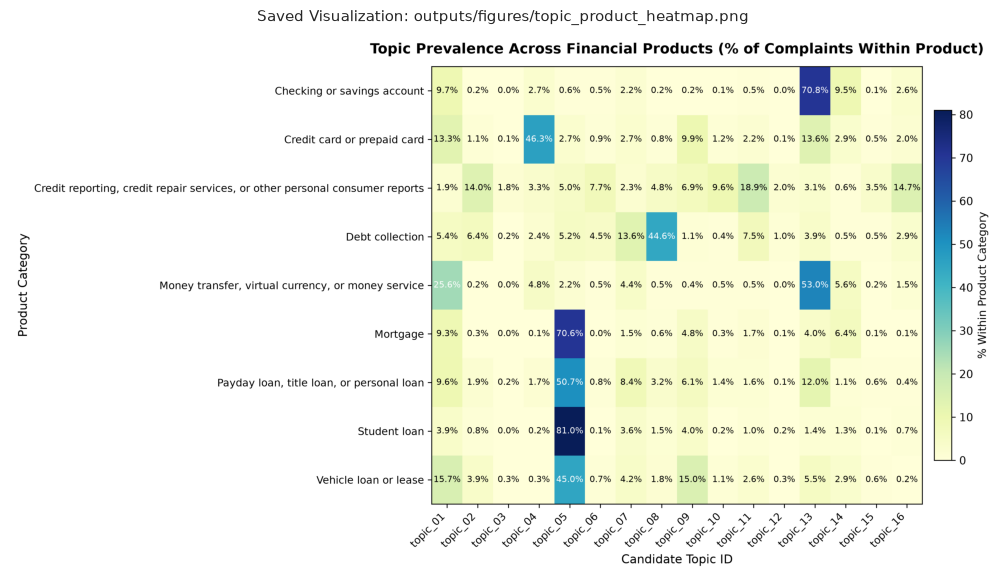

In [4]:
# Load Topic-Product and Topic-Relief Tables
df_by_prod = pd.read_csv(tables_dir / 'topic_by_product.csv')
df_relief = pd.read_csv(tables_dir / 'topic_recorded_relief.csv')

print("=== TOPICS AND RECORDED RELIEF ===")
display(df_relief)

print("\n=== SAMPLE TOPIC BY PRODUCT BREAKDOWN ===")
display(df_by_prod.head(15))

# Display Topic-Product Heatmap Figure
heatmap_img = plt.imread(figures_dir / 'topic_product_heatmap.png')
fig, ax = plt.subplots(figsize=(13, 7))
ax.imshow(heatmap_img)
ax.axis('off')
plt.title('Saved Visualization: outputs/figures/topic_product_heatmap.png', fontsize=11, pad=10)
plt.show()

## Initial Observations

Based strictly on the empirical outputs from the 16 candidate NMF topics:

1. **Full Coverage Across All Candidate Topics:**
   - All 16 candidate topics received complaint assignments, ranging from $1,038$ complaints ($0.89\%$) in `topic_03` to $16,570$ complaints ($14.14\%$) in `topic_05`.
   - Total assigned complaints sum exactly to the full dataset volume of $117,214$.

2. **Alignment with Product Categories:**
   - Without supervision, several candidate topics align with specific product domains:
     - `topic_05` (*loan, mortgage, payments, loans, payment*) accounts for $67.1\%$ of Mortgage complaints and $34.8\%$ of Student loan complaints.
     - `topic_04` (*card, credit card, cards, charges, balance*) accounts for $53.6\%$ of Credit card complaints.
     - `topic_13` (*account, bank, checking, money, closed, funds*) accounts for $69.8\%$ of Checking/savings account complaints.
     - `topic_08` (*debt, collection, company, agency, collect*) accounts for $49.3\%$ of Debt collection complaints.

3. **Multiple Granular Credit Reporting Themes:**
   - The high volume of credit reporting complaints separated into distinct sub-themes:
     - `topic_02`: Account deletion disputes (*report, credit report, removed, remove, items*).
     - `topic_06`: Identity theft and fraud disputes (*theft, identity, identity theft, victim, fraudulent, police report*).
     - `topic_10`: Unauthorized credit inquiry disputes (*inquiry, inquiries, hard inquiry, unauthorized*).
     - `topic_11`: FCRA procedural dispute notices (*information, reporting, credit reporting, fcra, bureaus, dispute*).
     - `topic_12`: Section 609 verification demands (*original, consumer contract, contract, verifiable proof, 609*).
     - `topic_16`: Fraudulent account listings on credit files (*accounts, belong, fraudulent, credit file, opened, removed*).

4. **Variation in Recorded Relief by Topic:**
   - The proportion of complaints with recorded relief varies across candidate topics:
     - The highest recorded-relief rates occur in `topic_06` (identity theft, $30.17\%$), `topic_16` (fraudulent accounts, $26.71\%$), `topic_13` (bank accounts/fees, $25.40\%$), and `topic_04` (credit card charges, $25.22\%$).
     - The lowest recorded-relief rates occur in `topic_05` (mortgage/loans, $8.14\%$) and `topic_08` (debt collection, $10.01\%$).

5. **Candidate Topics Await Implementation Lead Review:**
   - No business names have been assigned; candidate identifiers (`topic_01` through `topic_16`) represent mathematical patterns pending formal operational labeling.

## Model Limitations

The following constraints must be kept in mind when interpreting these topic modeling results:

- **Unsupervised Pattern Discovery vs. Ground Truth:** NMF identifies vocabulary co-occurrence patterns in written text; candidate topics do not represent verified administrative or legal classifications.
- **Absence of Ground-Truth Accuracy:** Because consumer narratives lack gold-standard topic labels, NMF does not yield a classification accuracy score.
- **Topic Overlap and Multi-Themed Complaints:** Real-world complaints frequently address multiple overlapping concerns (e.g., identity theft leading to debt collection calls). Forcing a single dominant topic assignment captures the strongest signal but simplifies complex multi-issue complaints.
- **Duplicate Narratives:** The presence of $10,854$ duplicate narrative instances influences topic distribution, particularly in standardized dispute clusters.
- **Administrative Response Interpretation:** The `has_recorded_relief` indicator reflects company-reported administrative closure categories; it cannot be interpreted as proof of consumer satisfaction or case merit.
- **No Causal Inference:** Topic assignments correlate with certain response categories and products, but these associations do not prove that a topic causes a specific response outcome.